Using device: cpu
Epoch 1/5 | Loss: 325.8984
Epoch 2/5 | Loss: 137.4355
Epoch 3/5 | Loss: 92.1621
Epoch 4/5 | Loss: 68.7988
Epoch 5/5 | Loss: 53.4461

Total Accuracy: 97.43%
Model saved as mnist_model.pth


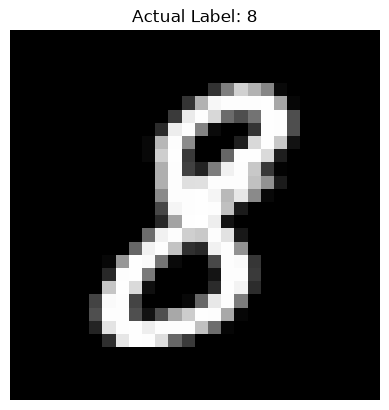

User picked image index: 110
Actual Label: 8
Model Prediction: 8


In [1]:

# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision.datasets import MNIST
from torchvision import transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt


# ==========================================
# 2. CHECK DEVICE
# ==========================================

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)


# ==========================================
# 3. DATA TRANSFORMATION
# ==========================================

transform = transforms.ToTensor()


# ==========================================
# 4. LOAD MNIST DATASET
# ==========================================

train_data = MNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_data = MNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)


# ==========================================
# 5. CREATE DATALOADERS
# ==========================================

train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=64,
    shuffle=False
)


# ==========================================
# 6. BUILD NEURAL NETWORK
# ==========================================

class DigitModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(28 * 28, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10)

        )

    def forward(self, x):
        return self.net(x)


# ==========================================
# 7. INITIALIZE MODEL
# ==========================================

model = DigitModel().to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)


# ==========================================
# 8. TRAIN MODEL
# ==========================================

epochs = 5

for epoch in range(epochs):

    model.train()

    total_loss = 0

    for images, labels in train_loader:

        images = images.view(images.size(0), -1).to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = loss_fn(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {total_loss:.4f}"
    )


# ==========================================
# 9. EVALUATE MODEL
# ==========================================

model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.view(images.size(0), -1).to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()

        total += labels.size(0)


# Calculate accuracy
accuracy = 100 * correct / total

print(f"\nTotal Accuracy: {accuracy:.2f}%")


# ==========================================
# 10. SAVE TRAINED MODEL
# ==========================================

torch.save(model.state_dict(), "mnist_model.pth")

print("Model saved as mnist_model.pth")


# ==========================================
# 11. DISPLAY TEST IMAGE
# ==========================================

index = 110

image, true_label = test_data[index]

plt.imshow(image.squeeze(), cmap="gray")

plt.title(f"Actual Label: {true_label}")

plt.axis("off")

plt.show()


# ==========================================
# 12. MAKE PREDICTION
# ==========================================

image_flat = image.view(1, -1).to(device)

model.eval()

with torch.no_grad():

    output = model(image_flat)

    predicted_label = output.argmax(dim=1).item()


# ==========================================
# 13. DISPLAY RESULTS
# ==========================================

print("User picked image index:", index)

print("Actual Label:", true_label)

print("Model Prediction:", predicted_label)
